# 03 - Supervised classification
Labels = cluster categories (corrected via `labeled_sample.csv`). Split 70/15/15
stratified, train LR / LinearSVM / RF / NB on **both** TF-IDF and embeddings, tune
with RandomizedSearchCV (5-fold), report metrics + confusion matrix, save the best
pipeline, and show sentiment per category.

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np
from src import DATA_PROCESSED, set_seed
from src import features as ft, classify as cf
from src.evaluate import sentiment_per_category, plot_sentiment_by_category
from src.predict import load_cluster_names
set_seed()
df = pd.read_csv(os.path.join(DATA_PROCESSED, 'reviews_clustered.csv'))
names = load_cluster_names()
df['label'] = df['cluster'].map(lambda c: names.get(int(c), f'cluster_{c}'))
print(df['label'].value_counts())

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/sudowoodo/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


label
positive feedback / praise            2424
app crashes & won't open              1587
task & scheduling feature requests    1412
usability & ease of use               1241
mixed / general impressions           1241
pricing & ads complaints              1190
calendar & event integration          1134
reminders & notifications broken       930
Name: count, dtype: int64


## 1. Re-apply manual corrections from labeled_sample.csv
Rows where a human filled `corrected_name` override the auto label.

In [3]:
ls_path = os.path.join(DATA_PROCESSED, 'labeled_sample.csv')
if os.path.exists(ls_path):
    ls = pd.read_csv(ls_path)
    fix = ls[ls['corrected_name'].notna() & (ls['corrected_name'] != '')]
    mapping = dict(zip(fix['raw_text'], fix['corrected_name']))
    df['label'] = df.apply(lambda r: mapping.get(r['raw_text'], r['label']), axis=1)
    print(f'applied {len(fix)} manual corrections')

applied 0 manual corrections


## 2. Features + stratified split

In [4]:
tfidf, vec = ft.build_tfidf(df['text'])
emb = ft.build_embeddings(df['raw_text'])
y = df['label'].values
t_tr, t_val, t_te, y_tr, y_val, y_te = cf.stratified_split(tfidf, y)
e_tr, e_val, e_te, _, _, _ = cf.stratified_split(emb, y)
print(y_tr[:5])

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|████████████████████████████| 175/175 [02:09<00:00,  1.35it/s]

['positive feedback / praise' 'pricing & ads complaints'
 'pricing & ads complaints' 'calendar & event integration'
 'task & scheduling feature requests']


## 3. Train + compare all models on both feature sets

In [10]:
features = {'tfidf': (t_tr, t_val), 'embedding': (e_tr, e_val)}
results, best_pipes = cf.train_and_compare(features, y_tr, n_iter=8)
features_val = {'tfidf': t_val, 'embedding': e_val}
results = cf.score_on(results, best_pipes, features_val, y_val)
results[['features','model','cv_f1_macro','accuracy','precision_macro','recall_macro','f1_macro']]

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/sklearn/model_selection/_search.py:327: UserWarning: The total space of parameters 6 is smaller than n_iter=8. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' s

,features,model,cv_f1_macro,accuracy,precision_macro,recall_macro,f1_macro
0,embedding,LogisticRegression,0.9644,0.9683,0.9653,0.9707,0.9677
1,embedding,NaiveBayes,0.9391,0.9385,0.9420,0.9391,0.9392
2,embedding,LinearSVM,0.9368,0.9450,0.9454,0.9430,0.9438
3,embedding,RandomForest,0.9150,0.9128,0.9159,0.9106,0.9129
4,tfidf,LogisticRegression,0.7381,0.7288,0.7343,0.7345,0.7322
5,tfidf,LinearSVM,0.7278,0.7252,0.7284,0.7232,0.7252
6,tfidf,RandomForest,0.7162,0.7121,0.7225,0.7191,0.7172
7,tfidf,NaiveBayes,0.6327,0.6314,0.6464,0.6287,0.6195


## 4. Evaluate the best model on the held-out test set

In [6]:
top = results.iloc[0]
key = f"{top['features']}::{top['model']}"
best_pipe = best_pipes[key]
X_test = t_te if top['features'] == 'tfidf' else e_te
labels = sorted(df['label'].unique())
summary = cf.evaluate_best(best_pipe, X_test, y_te, labels=labels)
print('TEST:', {k: v for k, v in summary.items() if k in
      ('accuracy','precision_macro','recall_macro','f1_macro')})
print(summary['report'])

TEST: {'accuracy': 0.9689, 'precision_macro': 0.9675, 'recall_macro': 0.9719, 'f1_macro': 0.9693}
                                    precision    recall  f1-score   support

          app crashes & won't open       0.95      0.97      0.96       238
      calendar & event integration       0.97      1.00      0.98       170
       mixed / general impressions       0.99      0.94      0.96       186
        positive feedback / praise       0.99      0.96      0.98       364
          pricing & ads complaints       0.97      0.99      0.98       179
  reminders & notifications broken       0.97      1.00      0.99       139
task & scheduling feature requests       0.97      0.93      0.95       212
           usability & ease of use       0.93      0.98      0.96       186

                          accuracy                           0.97      1674
                         macro avg       0.97      0.97      0.97      1674
                      weighted avg       0.97      0.97      0.9

## 5. Save the winning pipeline (+ vectorizer) with joblib

In [7]:
cf.save_best(best_pipe, top['features'])
ft.save_vectorizer(vec)
print('saved best pipeline for', top['features'], '/', top['model'])

saved best pipeline for embedding / LogisticRegression


## 6. Sentiment per category (VADER)

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/sudowoodo/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


col_0,positive,neutral,negative
label,,,
app crashes & won't open,35.8,25.4,38.8
calendar & event integration,63.0,12.9,24.2
mixed / general impressions,45.0,34.6,20.5
positive feedback / praise,84.1,4.9,11.0
pricing & ads complaints,51.3,14.5,34.1
reminders & notifications broken,48.8,14.9,36.2
task & scheduling feature requests,64.3,10.9,24.8
usability & ease of use,82.3,7.3,10.5


chart saved -> /home/sudowoodo/Pro/review-organizer/data/processed/figures/sentiment_by_category.png


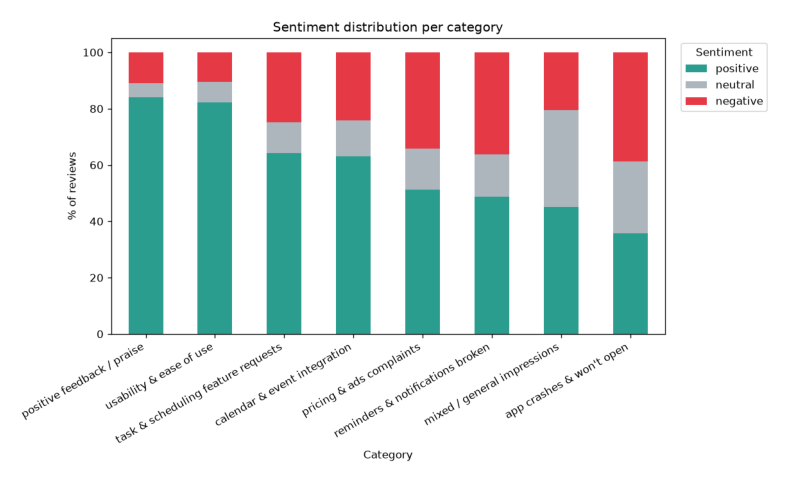

In [8]:
sent = sentiment_per_category(df, category_col='label', text_col='raw_text')
display(sent)
p = plot_sentiment_by_category(sent)
print('chart saved ->', p)
import matplotlib.image as mpimg, matplotlib.pyplot as plt
plt.figure(figsize=(10,6)); plt.imshow(mpimg.imread(p)); plt.axis('off'); plt.show()

## 7. Generalization test on freshly scraped reviews (step 9)
Run `python scripts/scrape_reviews.py` first; this applies the saved model.

In [9]:
import os
from src import DATA_RAW
from src.predict import Reviewer, distribution
scraped_path = os.path.join(DATA_RAW, 'scraped_reviews.csv')
if os.path.exists(scraped_path):
    scr = pd.read_csv(scraped_path)
    reviewer = Reviewer(feature_type=top['features'])
    pred = reviewer.predict_dataframe(scr, review_col='review')
    print('category distribution (%):\n', distribution(pred))
    # spot-check: fill a 'gold' column by hand for 100 rows, then:
    from src.predict import spot_check_accuracy
    print('spot-check accuracy:', spot_check_accuracy(pred, gold_col='gold'))
else:
    print('No scraped_reviews.csv yet - run scripts/scrape_reviews.py')

Batches: 100%|████████████████████████████████| 8/8 [00:04<00:00,  1.62it/s]


category distribution (%):
 category_name
mixed / general impressions           41.9
app crashes & won't open              20.6
positive feedback / praise            16.9
pricing & ads complaints              14.5
usability & ease of use                5.0
reminders & notifications broken       0.8
task & scheduling feature requests     0.2
Name: proportion, dtype: float64


KeyError: 'gold'

**Next (optional):** open `04_bert_colab.ipynb` in Google Colab.**Serving:** `streamlit run app.py`.